# Ordinary Kriging of critical raw materials - Lagunazo mine waste (pXRF data)

In [1]:
DATA_PATH = "Lagunazo_crm_samples_geographic5.csv"
KMZ_PATH  = "Lagunazo_waste_area.kmz"
GRID_PATH = "interpolation_grid_lagunazo_geographic2.csv"   # only if USE_FINE_GRID = False
CORE_PATH = "lagunazo_geostat_core.py"
OUT_DIR   = "results"

LON_COL, LAT_COL = "Lon", "Lat"

# [FIX B1] ELEMENTS accepts any of:
#     None           -> every column that is not a coordinate
#     "Bi"           -> a single element (a bare string is NO LONGER split into letters)
#     ["Sb", "Bi"]   -> an explicit list
# Names are matched against the file's columns case-insensitively and de-duplicated.
ELEMENTS = ["Sb", "Bi", "Co", "Cu", "Hf", "Mn", "Nb", "Ni", "Pd", "Sr", "Ta",
            "Ti", "V", "W", "Y"]

# Admission criteria. An element failing any of these is screened out and the
# reason recorded - it is never silently skipped.
MIN_STATIONS      = 10     # below this a variogram is not estimable at all
MIN_PAIRS_TOTAL   = 45     # = MIN_STATIONS choose 2
MIN_DISTINCT_VALS = 5      # guards against near-constant columns

# Elements below this are analysed but flagged: the variogram is dominated by
# sampling noise whatever the binning.
ADVISORY_STATIONS = 30

# projection
EPSG_UTM = "EPSG:32629"    # WGS 84 / UTM 29N, SW Spain

# station aggregation (replicate leakage into LOOCV)
STATION_TOL_M    = 5.0
AGGREGATE_METHOD = "mean"  # "mean" | "median"
NEGATIVE_POLICY  = "clip"  # "clip" (below-detection -> 0) | "drop" | "keep"

# transform
TRANSFORM_CANDIDATES = ["none", "log", "nscore"]
TRANSFORM_SELECT_ON  = "rmse_ppm"    # "rmse_ppm" | "rmse_fitspace" | "r2_ppm"
TRANSFORM_MIN_GAIN_PCT = 2.0         # a transform must beat "none" by this much
# [FIX S1] back-transform of a kriged mean under a LOG transform:
#   "journel" -> exp(y + s2/2 - mu) - c   ordinary kriging, Lagrange multiplier subtracted
#   "naive"   -> exp(y + s2/2) - c        SIMPLE-kriging correction (r6 behaviour; biased high)
#   "median"  -> exp(y) - c               median-unbiased, no correction
LOG_BACKTRANSFORM     = "journel"
NSCORE_TIE_METHOD     = "average"    # [FIX S2] tied values share one normal score
NSCORE_TAIL_EXPANSION = 1.0

# experimental variogram
N_LAGS_MAX     = 15        # ceiling; the pair budget may force fewer
MIN_PAIRS_LAG  = 30
AUTO_LAGS      = True
VGM_BINNING    = "equal_count"   # "equal_width" | "equal_count"
CUTOFF_FACTOR  = 0.50            # x maximum SAMPLE separation (not the bbox diagonal)
CHECK_ANISOTROPY = True

# model fitting
ALLOW_INVALID_2D_MODELS  = False  # keep the bounded-linear model out (CND in R^1 only)
GAUSSIAN_MIN_NUGGET_FRAC = 1e-3
RMSSE_PENALTY     = 0.15
SELECTION_TOL_PCT = 2.0           # models within this % of the best score are tied
STRICT_MODEL_ERRORS = True        # [FIX B3] re-raise programming errors

# kriging neighbourhood
MIN_NEIGHBORS        = 6
K_NEIGHBORS          = 16         # [FIX B2] was referenced but never defined
SEARCH_RADIUS_FACTOR = 1.6
MAX_COND_NUMBER      = 1e12

# estimation grid (shared by every element)
USE_FINE_GRID     = True
FINE_GRID_DIVISOR = 6.0    # target cell ~ median NN spacing / divisor
MIN_GRID_NODES    = 120    # applied to the LONGER axis
MAX_GRID_NODES    = 220    # applied to the LONGER axis

# output
MAKE_FIGURES   = True
FIG_DPI        = 200       # 400 for print; 200 keeps a 20-element run reasonable
EXPORT_RASTERS = True
# basemap
# NOTE: with SHOW_BASEMAP = True the FIGURES depend on a remote tile service, so
# they are no longer offline-reproducible. The analysis, rasters, tables and
# manifest stay bit-identical; only the imagery behind the data can change if
# the provider re-tiles. A failed fetch is reported and falls back to a plain
# background - it is never silently skipped.
SHOW_BASEMAP   = True
BASEMAP_SOURCE = "Esri.WorldImagery"   # dotted path into contextily.providers
BASEMAP_ALPHA  = 0.70                  # opacity of the tiles themselves
BASEMAP_ZOOM   = "auto"                # or an integer zoom level
SURFACE_ALPHA  = 0.82                  # opacity of the kriged surface over them

# maps
# [r8] The estimate and its uncertainty are written as SEPARATE figures.
UNCERTAINTY_MEASURE = "stderr"   # "stderr" (sqrt of kriging variance) | "variance"
MAP_FIGSIZE         = (10.5, 9.5)
N_GRADE_CLASSES = 7
N_SE_CLASSES    = 6
P90_BASIS       = "surface"   # "surface" | "sample"
P90_PCT         = 90.0

VERBOSE = True             # per-element console detail

In [2]:
import os, sys, io, json, time, hashlib, platform, warnings, contextlib
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
from scipy import stats
from scipy.stats import pearsonr, spearmanr, linregress

import shapely
import pyproj
from pyproj import Transformer
from shapely.geometry import Point
from shapely.prepared import prep

import lagunazo_geostat_core as gc

try:
    from shapely import contains_xy as _shapely_contains_xy
    HAVE_VECTOR_CONTAINS = True
except ImportError:
    HAVE_VECTOR_CONTAINS = False

try:
    import contextily as ctx
    HAVE_CTX = True
except ImportError:
    ctx, HAVE_CTX = None, False

try:
    display
except NameError:
    try:
        from IPython.display import display
    except ImportError:
        display = print

plt.rcParams.update({"figure.figsize": (10, 7), "font.size": 11,
                     "axes.axisbelow": True, "figure.dpi": 100,
                     "savefig.bbox": "tight"})

# [FIX B3] Programming errors must never be mistaken for a failed model fit.
PROGRAMMING_ERRORS = (NameError, TypeError, AttributeError, KeyError, IndexError,
                      ImportError)


def sha256(path, blocks=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(blocks), b""):
            h.update(chunk)
    return h.hexdigest()


RUN_STARTED = datetime.now(timezone.utc).isoformat(timespec="seconds")
ENV = {
    "run_started_utc": RUN_STARTED,
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__, "shapely": shapely.__version__,
    "pyproj": pyproj.__version__,
    "contextily": (ctx.__version__ if HAVE_CTX else "not installed"),
}

_needed = [DATA_PATH, KMZ_PATH, CORE_PATH] + ([] if USE_FINE_GRID else [GRID_PATH])
INPUTS = {}
for _p in _needed:
    INPUTS[_p] = dict(sha256=sha256(_p), bytes=os.path.getsize(_p)) \
        if os.path.exists(_p) else dict(sha256=None, bytes=None, missing=True)

_missing = [k for k, v in INPUTS.items() if v.get("missing")]
if _missing:
    raise FileNotFoundError(
        "Input file(s) not found in the working directory: " + ", ".join(_missing)
        + "\nPut them next to the notebook, or edit the paths in the configuration cell.")

os.makedirs(OUT_DIR, exist_ok=True)

print("Environment")
for k, v in ENV.items():
    print(f"  {k:16s} {v}")
print("\nInputs")
for k, v in INPUTS.items():
    print(f"  {k:45s} {v['bytes']:>9,} B   sha256 {v['sha256'][:16]}...")
print(f"\nvectorised point-in-polygon: {'yes' if HAVE_VECTOR_CONTAINS else 'no'}"
      f"   basemaps: {'available' if HAVE_CTX else 'not installed'} "
      f"(SHOW_BASEMAP={SHOW_BASEMAP})")
print(f"log back-transform: {LOG_BACKTRANSFORM}   nscore ties: {NSCORE_TIE_METHOD}   "
      f"strict model errors: {STRICT_MODEL_ERRORS}")

Environment
  run_started_utc  2026-09-03T12:20:12+00:00
  python           3.12.2
  platform         Windows-11-10.0.26220-SP0
  numpy            1.26.4
  pandas           2.2.1
  scipy            1.12.0
  matplotlib       3.8.3
  shapely          2.0.3
  pyproj           3.6.1
  contextily       1.7.0

Inputs
  Lagunazo_crm_samples_geographic5.csv             40,011 B   sha256 6525f985110c6ef1...
  Lagunazo_waste_area.kmz                           3,117 B   sha256 51ddd54e57f53a8c...
  lagunazo_geostat_core.py                         72,075 B   sha256 5bf87b4f54fb23c3...

vectorised point-in-polygon: yes   basemaps: available (SHOW_BASEMAP=True)
log back-transform: journel   nscore ties: average   strict model errors: True


## Shared setup

The assay table, the waste polygon and the estimation grid are built **once** and reused by
every element. The grid is derived from all sampled locations rather than from the selected
elements, so it does not move when the element list changes: every element raster stays
co-registered and the exports can be stacked, differenced or correlated without resampling.

In [3]:
to_utm = Transformer.from_crs("EPSG:4326", EPSG_UTM, always_xy=True)
to_ll = Transformer.from_crs(EPSG_UTM, "EPSG:4326", always_xy=True)


def resolve_elements(spec, available):
    """[FIX B1] Accept None | str | iterable of str. Never iterate a bare string
    into characters. Match case-insensitively, strip whitespace, de-duplicate
    while preserving order, and return the unknown names for reporting."""
    if spec is None:
        return list(available), []
    if isinstance(spec, str):
        spec = [spec]
    lut = {str(c).strip().lower(): c for c in available}
    chosen, unknown, seen = [], [], set()
    for raw in spec:
        col = lut.get(str(raw).strip().lower())
        if col is None:
            unknown.append(str(raw))
        elif col not in seen:
            seen.add(col)
            chosen.append(col)
    return chosen, unknown


# assay table
RAW = pd.read_csv(DATA_PATH)
RAW = RAW.loc[:, ~RAW.columns.str.contains(r"^Unnamed", case=False, regex=True)].copy()
RAW = RAW.replace(r"^\s*$", np.nan, regex=True)
for c in (LON_COL, LAT_COL):
    if c not in RAW.columns:
        raise ValueError(f"Coordinate column {c!r} not found. Columns: {list(RAW.columns)}")
    RAW[c] = pd.to_numeric(RAW[c], errors="coerce")

ALL_ELEMENTS = [c for c in RAW.columns if c not in (LON_COL, LAT_COL)]
ELEMENT_LIST, UNKNOWN_ELEMENTS = resolve_elements(ELEMENTS, ALL_ELEMENTS)
if UNKNOWN_ELEMENTS:
    raise ValueError(f"Requested element(s) not in {DATA_PATH}: {UNKNOWN_ELEMENTS}\n"
                     f"Available: {ALL_ELEMENTS}")
if not ELEMENT_LIST:
    raise ValueError("ELEMENTS resolved to an empty list.")

# waste polygon, holes preserved
POLY_LL = gc.read_polygon_from_kmz(KMZ_PATH, verbose=True)
POLY = gc.reproject_polygon(POLY_LL, to_utm)
PX, PY = np.asarray(POLY.exterior.coords)[:, 0], np.asarray(POLY.exterior.coords)[:, 1]
HOLES = [(np.asarray(r.coords)[:, 0], np.asarray(r.coords)[:, 1]) for r in POLY.interiors]
POLY_PATH = gc.mpl_path_from_polygon(POLY)
XMIN, YMIN, XMAX, YMAX = POLY.bounds
PAD_X, PAD_Y = (XMAX - XMIN) * 0.06, (YMAX - YMIN) * 0.06

# one grid for every element
_lo = RAW[LON_COL].to_numpy(float)
_la = RAW[LAT_COL].to_numpy(float)
_m = np.isfinite(_lo) & np.isfinite(_la)
_ax, _ay = to_utm.transform(_lo[_m], _la[_m])
_all_xy = np.unique(np.round(np.column_stack([_ax, _ay]), 3), axis=0)
_d, _ = cKDTree(_all_xy).query(_all_xy, k=min(2, len(_all_xy)))
_nn = np.asarray(_d)[:, -1]
_nn = _nn[np.isfinite(_nn) & (_nn > 0)]
MEDIAN_SPACING_ALL = float(np.median(_nn)) if _nn.size else 25.0

if USE_FINE_GRID:
    _w, _h = XMAX - XMIN, YMAX - YMIN
    _long = max(_w, _h)
    _n_long = int(np.clip(np.ceil(_long / (MEDIAN_SPACING_ALL / FINE_GRID_DIVISOR)) + 1,
                          MIN_GRID_NODES, MAX_GRID_NODES))
    STEP = _long / (_n_long - 1)
    GX = XMIN + np.arange(int(np.floor(_w / STEP)) + 1) * STEP
    GY = YMIN + np.arange(int(np.floor(_h / STEP)) + 1) * STEP
    GRID_SOURCE = f"regular grid {len(GX)} x {len(GY)} from KMZ bounds, square cells {STEP:.3f} m"
else:
    _g = pd.read_csv(GRID_PATH)
    if {"Var1", "Var2"}.issubset(_g.columns):
        _gl = pd.to_numeric(_g["Var1"], errors="coerce")
        _gt = pd.to_numeric(_g["Var2"], errors="coerce")
    elif {LON_COL, LAT_COL}.issubset(_g.columns):
        _gl = pd.to_numeric(_g[LON_COL], errors="coerce")
        _gt = pd.to_numeric(_g[LAT_COL], errors="coerce")
    else:
        raise ValueError("Grid file must contain Var1/Var2 or Lon/Lat columns.")
    _ok = np.isfinite(_gl) & np.isfinite(_gt)
    _gxu, _gyu = to_utm.transform(_gl[_ok].to_numpy(), _gt[_ok].to_numpy())
    GX, GY = np.unique(np.round(_gxu, 3)), np.unique(np.round(_gyu, 3))
    STEP = float(np.median(np.diff(GX)))
    GRID_SOURCE = f"external grid file ({len(GX)} x {len(GY)})"

X2D, Y2D = np.meshgrid(GX, GY)
GRID_PTS = np.column_stack([X2D.ravel(), Y2D.ravel()])
CELL_X = float(np.median(np.diff(GX))) if len(GX) > 1 else np.nan
CELL_Y = float(np.median(np.diff(GY))) if len(GY) > 1 else np.nan
SQUARE_CELLS = bool(np.isfinite(CELL_X) and np.isfinite(CELL_Y)
                    and abs(CELL_Y - CELL_X) < 1e-6 * CELL_X)
CELLSIZE = CELL_X
if not SQUARE_CELLS:
    warnings.warn(f"Grid cells are not square (dx={CELL_X:.4f}, dy={CELL_Y:.4f}); "
                  "ESRI ASCII export will be skipped.")

if HAVE_VECTOR_CONTAINS:
    INSIDE = _shapely_contains_xy(POLY, GRID_PTS[:, 0], GRID_PTS[:, 1])
else:
    _pp = prep(POLY)
    INSIDE = np.array([_pp.contains(Point(xy)) for xy in GRID_PTS], dtype=bool)

DOMAIN_DIAG = float(np.hypot(XMAX - XMIN, YMAX - YMIN))

# context handed to every plotting routine, so the core module reads no globals
MAP = dict(XMIN=XMIN, XMAX=XMAX, YMIN=YMIN, YMAX=YMAX, PAD_X=PAD_X, PAD_Y=PAD_Y,
           PX=PX, PY=PY, HOLES=HOLES, POLY_PATH=POLY_PATH, X2D=X2D, Y2D=Y2D,
           SHOW_BASEMAP=SHOW_BASEMAP, HAVE_CTX=HAVE_CTX, ctx=ctx, EPSG_UTM=EPSG_UTM,
           FIG_DPI=FIG_DPI, N_GRADE_CLASSES=N_GRADE_CLASSES, N_SE_CLASSES=N_SE_CLASSES,
           MIN_PAIRS_LAG=MIN_PAIRS_LAG, VGM_BINNING=VGM_BINNING,
           P90_PCT=P90_PCT, P90_BASIS=P90_BASIS,
           BASEMAP_SOURCE=BASEMAP_SOURCE, BASEMAP_ALPHA=BASEMAP_ALPHA,
           BASEMAP_ZOOM=BASEMAP_ZOOM, SURFACE_ALPHA=SURFACE_ALPHA,
           UNCERTAINTY_MEASURE=UNCERTAINTY_MEASURE, MAP_FIGSIZE=MAP_FIGSIZE)

print(f"Assay table        : {len(RAW):,} rows, {len(ALL_ELEMENTS)} element columns")
print(f"Elements requested : {len(ELEMENT_LIST)}  ({', '.join(ELEMENT_LIST)})")
print(f"Waste polygon      : {POLY.area/1e4:.1f} ha"
      + (f"  ({len(HOLES)} hole(s) preserved)" if HOLES else "  (no holes)"))
print(f"UTM extent         : E {XMIN:.0f}-{XMAX:.0f}   N {YMIN:.0f}-{YMAX:.0f}")
print(f"Median NN spacing  : {MEDIAN_SPACING_ALL:.1f} m  (all sampled locations)")
print(f"Grid               : {GRID_SOURCE}")
print(f"                     cells {'square' if SQUARE_CELLS else 'NOT SQUARE'}, "
      f"{int(INSIDE.sum()):,} of {len(GRID_PTS):,} nodes inside the polygon")

Assay table        : 274 rows, 20 element columns
Elements requested : 15  (Sb, Bi, Co, Cu, Hf, Mn, Nb, Ni, Pd, Sr, Ta, Ti, V, W, Y)
Waste polygon      : 16.2 ha  (no holes)
UTM extent         : E 661413-661987   N 4165350-4165877
Median NN spacing  : 14.5 m  (all sampled locations)
Grid               : regular grid 220 x 202 from KMZ bounds, square cells 2.622 m
                     cells square, 23,646 of 44,440 nodes inside the polygon


## The per-element engine

Three functions, kept deliberately small so each can be tested on its own:

| Function | Does |
|---|---|
| `build_stations(el)` | Extract one element, collapse replicates to stations at `STATION_TOL_M`, return coordinates and values plus a screening verdict |
| `analyse(coords, values, transform)` | Decluster → transform → experimental variogram → fit 5 models → LOOCV → select. **No gridding**, so it is cheap enough to run for every element × transform |
| `krige_grid(coords, values, fit)` | Krige the shared grid with one chosen model, back-transform, clip in data space |

`analyse` excludes the grid, which is the expensive step. Selecting the transform needs only the
cross-validation, so the grid is computed once per element rather than three times.

In [4]:
SCREEN_OK = "ok"


def build_stations(el):
    """One element -> station means, with an explicit screening verdict."""
    d = RAW[[LON_COL, LAT_COL, el]].copy()
    d[el] = pd.to_numeric(d[el], errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna()
    rep = dict(element=el, n_rows=int(len(RAW)), n_valid=int(len(d)))
    if len(d) < MIN_STATIONS:
        rep.update(status=f"only {len(d)} valid measurement(s)", n_stations=0,
                   n_pairs=0)
        return None, rep

    x, y = to_utm.transform(d[LON_COL].to_numpy(float), d[LAT_COL].to_numpy(float))
    d = d.assign(_X=x, _Y=y)
    with contextlib.redirect_stdout(io.StringIO()):
        st, srep = gc.station_means(d, "_X", "_Y", el, tol_m=STATION_TOL_M,
                                    coords_are_metres=True, agg=AGGREGATE_METHOD)
    v = st[el].to_numpy(float)
    n_neg = int(np.sum(v < 0))
    if NEGATIVE_POLICY == "clip":
        v = np.clip(v, 0.0, None)
    elif NEGATIVE_POLICY == "drop" and n_neg:
        keep = v >= 0
        st, v = st.loc[keep].reset_index(drop=True), v[keep]
    coords = np.column_stack([st["_X"].to_numpy(float), st["_Y"].to_numpy(float)])
    n = len(v)
    n_pairs = n * (n - 1) // 2
    rep.update(n_stations=n, n_pairs=n_pairs, n_negative=n_neg,
               negative_policy=NEGATIVE_POLICY,
               n_with_reps=srep["n_stations_with_reps"], max_reps=srep["max_reps"],
               median_rep_sd=srep["median_rep_sd"],
               mean=float(v.mean()) if n else np.nan,
               median=float(np.median(v)) if n else np.nan,
               sd=float(v.std(ddof=1)) if n > 1 else np.nan,
               vmin=float(v.min()) if n else np.nan,
               vmax=float(v.max()) if n else np.nan,
               skew=float(stats.skew(v)) if n > 2 else np.nan)
    rep["cv"] = rep["sd"] / rep["mean"] if rep["mean"] else np.nan

    # admission criteria, each reported rather than silently applied
    if n < MIN_STATIONS:
        rep["status"] = f"{n} stations < MIN_STATIONS={MIN_STATIONS}"
    elif n_pairs < MIN_PAIRS_TOTAL:
        rep["status"] = f"{n_pairs} pairs < MIN_PAIRS_TOTAL={MIN_PAIRS_TOTAL}"
    elif len(np.unique(v)) < MIN_DISTINCT_VALS:
        rep["status"] = f"only {len(np.unique(v))} distinct values"
    elif not np.isfinite(rep["sd"]) or rep["sd"] <= 0:
        rep["status"] = "zero variance"
    else:
        rep["status"] = SCREEN_OK
        rep["advisory"] = (f"{n} stations < {ADVISORY_STATIONS}: variogram dominated by "
                           "sampling noise") if n < ADVISORY_STATIONS else ""
        var_tot = float(np.var(v, ddof=1))
        imax = int(np.argmax(np.abs(v - v.mean())))
        rep["top1_variance_share"] = float(((v[imax] - v.mean()) ** 2 / (n - 1)) / var_tot) \
            if var_tot > 0 else np.nan

    if rep["status"] != SCREEN_OK:
        return None, rep
    return (coords, v, st), rep


def _pairs_max_sep(coords):
    iu = np.triu_indices(len(coords), k=1)
    h = np.hypot(coords[iu[0], 0] - coords[iu[1], 0],
                 coords[iu[0], 1] - coords[iu[1], 1])
    return float(h.max()), int(h.size)


def analyse(coords, values, transform, el="", verbose=False):
    """Decluster, transform, variogram, fit, LOOCV, select. No gridding."""
    out = dict(element=el, transform=transform)
    n = len(values)

    w, drep = gc.declustering_weights(coords, values=values, target="min_mean",
                                      verbose=False, return_report=True)
    dstats = gc.declustered_stats(values, w)
    out.update(declus_cell_m=drep["cell_size"], declus_optimised=drep["optimised"],
               eff_n=drep["eff_n"], naive_mean=dstats["naive_mean"],
               declustered_mean=dstats["declustered_mean"],
               declus_effect_pct=dstats["effect_pct"])

    tf = gc.Transform(transform, tail_expansion=NSCORE_TAIL_EXPANSION,
                      log_mode=LOG_BACKTRANSFORM,
                      tie_method=NSCORE_TIE_METHOD).fit(values)
    y = tf.forward(values)
    out["tf"] = tf
    out["transform_note"] = tf.note()

    max_sep, n_pairs = _pairs_max_sep(coords)
    cutoff = CUTOFF_FACTOR * max_sep
    # [FIX S6] suggest_n_lags is now actually used, as the ceiling
    n_lags_ceiling = int(min(N_LAGS_MAX, gc.suggest_n_lags(
        n, CUTOFF_FACTOR, MIN_PAIRS_LAG, N_LAGS_MAX)))
    with contextlib.redirect_stdout(io.StringIO()) as _b:
        cen, gam, cnt, rel, cutoff, svar = gc.experimental_variogram(
            coords, y, n_lags=n_lags_ceiling, cutoff=cutoff, min_pairs=MIN_PAIRS_LAG,
            weights=w, binning=VGM_BINNING, auto_lags=AUTO_LAGS, verbose=True)
    out["vgm_log"] = _b.getvalue()
    out.update(max_sep_m=max_sep, n_pairs=n_pairs, cutoff_m=cutoff,
               sample_variance=svar, lag_centers=cen, lag_gamma=gam, lag_counts=cnt,
               lag_reliable=rel, n_lags_ceiling=n_lags_ceiling,
               n_lags_used=int(np.sum(rel & np.isfinite(gam))),
               n_lags_computed=int(np.sum(cnt > 0)))
    occ = np.where(cnt > 0)[0]
    out["first_lag_over_variance"] = (float(gam[occ[0]] / svar)
                                      if occ.size and svar > 0 else np.nan)
    ok_lags = np.isfinite(gam) & (cnt > 0)
    out["median_gamma_over_variance"] = (float(np.median(gam[ok_lags] / svar))
                                         if ok_lags.any() and svar > 0 else np.nan)

    mask = np.isfinite(cen) & np.isfinite(gam) & rel
    xf, yf, wf = cen[mask], gam[mask], cnt[mask].astype(float)
    if len(xf) < 3:
        out["status"] = f"only {len(xf)} lag(s) meet the {MIN_PAIRS_LAG}-pair rule"
        return out

    # bounds: nugget + PARTIAL sill, so psill >= 0 by construction
    g_max = float(np.max(yf))
    nugget_hi = float(max(g_max * 1.05, 1e-12))
    psill_hi = float(max(g_max * 1.5, 1e-12))
    nugget0 = float(np.clip(min(yf[0], np.percentile(yf, 25)), 0.0, nugget_hi))
    psill0 = float(np.clip(max(np.median(yf[-min(3, len(yf)):]) - nugget0, g_max * 0.05),
                           0.0, psill_hi))
    dx = float(np.median(np.diff(np.sort(xf)))) if len(xf) > 1 else float(xf.max())
    range_lo = float(max(dx * 0.5, 1e-3))
    range_hi = float(max(cutoff * 1.5, range_lo * 4))
    range0 = float(np.clip(0.4 * xf.max(), range_lo, range_hi))
    lower, upper = [0.0, 0.0, range_lo], [nugget_hi, psill_hi, range_hi]
    p0 = [float(np.clip(v_, lower[i], upper[i]))
          for i, v_ in enumerate([nugget0, psill0, range0])]
    sigma = 1.0 / np.sqrt(np.maximum(wf, 1e-9))
    out.update(fit_lags=len(xf), bounds=dict(nugget=[0.0, nugget_hi],
                                             psill=[0.0, psill_hi],
                                             rng=[range_lo, range_hi]))

    results, failures = [], []
    for name, (fn, valid2d, _note) in gc.VGM_MODELS.items():
        if not (valid2d or ALLOW_INVALID_2D_MODELS):
            continue
        try:
            if name == "Nugget":
                nug, ps = float(np.average(yf, weights=wf)), 0.0
                rg, hits = float(cutoff), []
            else:
                lo, hi = list(lower), list(upper)
                if name == "Gaussian":
                    lo[0] = max(lo[0], GAUSSIAN_MIN_NUGGET_FRAC * max(g_max, 1e-12))
                pp = [float(np.clip(p0[j], lo[j], hi[j])) for j in range(3)]
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    popt, _ = curve_fit(fn, xf, yf, p0=pp, sigma=sigma,
                                        absolute_sigma=False, bounds=(lo, hi),
                                        maxfev=200000)
                nug, ps, rg = (float(v_) for v_ in popt)
                hits = gc.fit_report(name, popt, lo, hi, verbose=False)
            sill = nug + ps
            radius = max(rg * SEARCH_RADIUS_FACTOR, MEDIAN_SPACING_ALL * 5.0)
            pred, kvar, mu, nnb, n_sing = gc.loocv_ok(
                coords, y, fn, nug, ps, rg, min_neighbors=MIN_NEIGHBORS,
                k_neighbors=K_NEIGHBORS, search_radius=radius,
                max_cond=MAX_COND_NUMBER)
            fin = np.isfinite(pred)
            if not fin.any():
                raise RuntimeError("LOOCV returned no finite predictions")
            err = pred[fin] - y[fin]
            se2 = err ** 2
            rmse = float(np.sqrt(np.mean(se2)))
            se_rmse = float(np.std(se2, ddof=1) / np.sqrt(se2.size) / (2 * rmse)) \
                if se2.size > 1 and rmse > 0 else np.nan
            sst = float(np.sum((y[fin] - y[fin].mean()) ** 2))
            r2 = float(1 - np.sum(se2) / sst) if sst > 0 else np.nan
            sm = kvar[fin] > 0
            rmsse = float(np.sqrt(np.mean((err[sm] / np.sqrt(kvar[fin][sm])) ** 2))) \
                if sm.any() else np.nan
            score = rmse * (1 + RMSSE_PENALTY *
                            abs((rmsse if np.isfinite(rmsse) else 1.0) - 1.0))
            results.append(dict(name=name, fn=fn, nugget=nug, psill=ps, sill=sill,
                                rng=rg, ns=nug / sill if sill > 0 else np.nan,
                                rmse=rmse, se_rmse=se_rmse, r2=r2, rmsse=rmsse,
                                score=score, pred=pred, kvar=kvar, mu=mu, nnb=nnb,
                                radius=radius, bound_hits=hits, n_singular=n_sing))
        except PROGRAMMING_ERRORS as exc:
            # [FIX B3] a coding error is NOT a failed model fit
            failures.append(f"{name}: {type(exc).__name__}: {exc}  [PROGRAMMING ERROR]")
            if STRICT_MODEL_ERRORS:
                raise
        except Exception as exc:
            failures.append(f"{name}: {type(exc).__name__}: {exc}")
            if verbose:
                print(f"    {el}/{transform}/{name} failed: {type(exc).__name__}: {exc}")

    out["model_failures"] = failures
    if not results:
        out["status"] = "all model fits failed - " + ("; ".join(failures)
                                                      or "no candidate models")
        return out

    results.sort(key=lambda d_: d_["score"])
    tied = [r for r in results
            if r["score"] <= results[0]["score"] * (1 + SELECTION_TOL_PCT / 100)]
    best = sorted(tied, key=lambda d_: gc.MODEL_PREFERENCE.index(d_["name"])
                  if d_["name"] in gc.MODEL_PREFERENCE else 99)[0]

    # back-transform the LOOCV predictions into ppm [FIX S1: mu is supplied]
    fin = np.isfinite(best["pred"])
    if transform == "none":
        pred_ppm = best["pred"][fin].copy()
    else:
        pred_ppm = tf.back(best["pred"][fin], var=best["kvar"][fin],
                           lagrange=best["mu"][fin])
    n_clip = int(np.sum(pred_ppm < 0))
    pred_ppm = np.clip(pred_ppm, 0.0, None)
    obs_ppm = values[fin]
    err_ppm = pred_ppm - obs_ppm
    rmse_ppm = float(np.sqrt(np.mean(err_ppm ** 2)))
    sst_ppm = float(np.sum((obs_ppm - obs_ppm.mean()) ** 2))
    nug_res = next((r for r in results if r["name"] == "Nugget"), None)

    out.update(
        status=SCREEN_OK, results=results, tied=[r["name"] for r in tied], best=best,
        model=best["name"], nugget=best["nugget"], psill=best["psill"],
        sill=best["sill"], rng=best["rng"], ns_ratio=best["ns"],
        bound_hits=", ".join(p for p, _s, _b in best["bound_hits"]) or "",
        rmse_fit=best["rmse"], se_rmse_fit=best["se_rmse"], r2_fit=best["r2"],
        rmsse=best["rmsse"], n_singular=best["n_singular"],
        nugget_bench_rmse=(nug_res["rmse"] if nug_res else np.nan),
        gain_vs_nugget_pct=(100 * (nug_res["rmse"] - best["rmse"]) / nug_res["rmse"]
                            if nug_res and nug_res["rmse"] > 0 else np.nan),
        pred_ppm=pred_ppm, obs_ppm=obs_ppm, kvar_cv=best["kvar"][fin],
        mu_cv=best["mu"][fin], pred_fit=best["pred"][fin], obs_fit=y[fin],
        cv_mask=fin, n_clip_cv=n_clip, rmse_ppm=rmse_ppm,
        rmse_mean_model_ppm=float(np.sqrt(np.mean((obs_ppm - obs_ppm.mean()) ** 2))),
        r2_ppm=float(1 - np.sum(err_ppm ** 2) / sst_ppm) if sst_ppm > 0 else np.nan,
        me_ppm=float(err_ppm.mean()), mae_ppm=float(np.mean(np.abs(err_ppm))),
        pearson_ppm=float(pearsonr(obs_ppm, pred_ppm)[0])
        if obs_ppm.size > 1 and obs_ppm.std() > 0 and pred_ppm.std() > 0 else np.nan,
        spearman_ppm=float(spearmanr(obs_ppm, pred_ppm)[0]) if obs_ppm.size > 2 else np.nan,
        slope_ppm=float(linregress(obs_ppm, pred_ppm)[0]) if obs_ppm.size > 1 else np.nan,
        weights=w,
    )
    kv = out["kvar_cv"]
    sm = kv > 0
    if sm.any():
        z = (out["pred_fit"][sm] - out["obs_fit"][sm]) / np.sqrt(kv[sm])
        out.update(ase=float(np.mean(np.sqrt(kv[sm]))),
                   mean_std_err=float(np.mean(z)),
                   coverage95=float(100 * np.mean(np.abs(z) <= 1.959964)))

    if CHECK_ANISOTROPY:
        try:
            dv = gc.directional_variograms(coords, y, cutoff=cutoff)
            with contextlib.redirect_stdout(io.StringIO()) as _ab:
                rows = gc.anisotropy_report(dv, svar)
            out["aniso_log"] = _ab.getvalue()
            vals_ = [r[1] for r in rows if np.isfinite(r[1])]
            out["aniso_contrast"] = (max(vals_) / min(vals_)
                                     if len(vals_) >= 2 and min(vals_) > 0 else np.nan)
            out["aniso_dirs"] = len(rows)
        except PROGRAMMING_ERRORS:
            raise
        except Exception:
            out["aniso_contrast"], out["aniso_dirs"] = np.nan, 0
            out["aniso_log"] = "anisotropy screening failed\n"
    return out

In [5]:
def krige_grid(coords, values, fit, progress=False):
    """Krige the shared grid with one fitted model; back-transform, then clip."""
    tf = fit["tf"]
    y = tf.forward(values)
    radius = max(fit["rng"] * SEARCH_RADIUS_FACTOR, MEDIAN_SPACING_ALL * 5.0)
    est, var, mu, nnb, diag = gc.krige_points(
        GRID_PTS, coords, y, fit["best"]["fn"], fit["nugget"], fit["psill"], fit["rng"],
        min_neighbors=MIN_NEIGHBORS, k_neighbors=K_NEIGHBORS, search_radius=radius,
        mask=INSIDE, exact=True, max_cond=MAX_COND_NUMBER, clip_min=None,
        progress_every=2000 if progress else 0)

    Zfit = est.reshape(X2D.shape)
    KV = var.reshape(X2D.shape)
    MU = mu.reshape(X2D.shape)
    SE = np.sqrt(np.maximum(KV, 0.0))     # FIT space; ppm only when transform is none
    if fit["transform"] == "none":
        Z = Zfit.copy()
    else:
        Z = tf.back(Zfit, var=KV, lagrange=MU)          # [FIX S1]
    n_neg = int(np.sum(np.isfinite(Z) & (Z < 0)))
    if n_neg:
        Z = np.where(np.isfinite(Z), np.clip(Z, 0.0, None), np.nan)
    se_unit = "ppm" if fit["transform"] == "none" else f"{fit['transform']}-space"
    return dict(Z=Z, Zfit=Zfit, KV=KV, MU=MU, SE=SE, nnb=nnb.reshape(X2D.shape),
                diag=diag, n_clipped_grid=n_neg, search_radius=radius,
                radius_is_global=bool(radius >= DOMAIN_DIAG), se_unit=se_unit)


def elem_dir(el):
    d = os.path.join(OUT_DIR, el)
    os.makedirs(d, exist_ok=True)
    return d

## Stage 1 - Screening

Every element is put through the same admission test and the verdict recorded. An element that
fails is never silently dropped; the reason appears in the table and in the manifest.

In [6]:
# STAGE 1: SCREENING
STATIONS, SCREEN = {}, []

for el in ELEMENT_LIST:
    payload, rep = build_stations(el)
    SCREEN.append(rep)
    if payload is not None:
        STATIONS[el] = payload

screen_df = pd.DataFrame(SCREEN)
cols = ["element", "n_valid", "n_stations", "n_pairs", "n_with_reps", "median_rep_sd",
        "n_negative", "mean", "median", "sd", "cv", "skew", "vmin", "vmax",
        "top1_variance_share", "status"]
screen_df = screen_df.reindex(columns=[c for c in cols if c in screen_df.columns])
if len(screen_df) and "n_stations" in screen_df.columns:
    screen_df = screen_df.sort_values("n_stations", ascending=False, na_position="last")
for c in ["mean", "median", "sd", "vmin", "vmax"]:
    if c in screen_df:
        screen_df[c] = pd.to_numeric(screen_df[c], errors="coerce").round(1)
for c in ["cv", "skew", "median_rep_sd", "top1_variance_share"]:
    if c in screen_df:
        screen_df[c] = pd.to_numeric(screen_df[c], errors="coerce").round(2)
display(screen_df)
screen_df.to_csv(os.path.join(OUT_DIR, "screening.csv"), index=False)

ADMITTED = [r["element"] for r in SCREEN if r["status"] == SCREEN_OK]
REJECTED = [(r["element"], r["status"]) for r in SCREEN if r["status"] != SCREEN_OK]
print(f"\nAdmitted : {len(ADMITTED)}  ({', '.join(ADMITTED) if ADMITTED else '-'})")
if REJECTED:
    print("Rejected :")
    for e, why in REJECTED:
        print(f"  {e:4s} {why}")
if not ADMITTED:
    raise RuntimeError("No element passed screening - nothing to krige. Loosen "
                       "MIN_STATIONS / MIN_PAIRS_TOTAL or widen ELEMENTS.")

adv = [(r["element"], r["n_stations"]) for r in SCREEN
       if r["status"] == SCREEN_OK and r.get("advisory")]
if adv:
    print(f"\nAdmitted but under {ADVISORY_STATIONS} stations - variogram dominated by "
          f"sampling noise:")
    print("  " + ", ".join(f"{e} ({n})" for e, n in adv))
hi_lev = [(r["element"], r["top1_variance_share"]) for r in SCREEN
          if r["status"] == SCREEN_OK and r.get("top1_variance_share", 0) > 0.20]
if hi_lev:
    print("\nOne station supplies over 20 % of the variance (domain or transform first):")
    print("  " + ", ".join(f"{e} ({100*s:.0f} %)" for e, s in hi_lev))

# [FIX S6] distribution_report is now actually run
if VERBOSE:
    print("\n" + "=" * 78)
    for el in ADMITTED:
        gc.distribution_report(STATIONS[el][1], label=f"{el} (station means, ppm)")
        print("-" * 78)

,element,n_valid,n_stations,n_pairs,n_with_reps,median_rep_sd,n_negative,mean,median,sd,cv,skew,vmin,vmax,top1_variance_share,status
3,Cu,247,68,2278,67.0,55.09,0.0,476.4,363.3,429.7,0.90,1.65,11.6,2112.9,0.22,ok
11,Ti,253,67,2211,66.0,457.67,0.0,3878.8,2989.2,3325.4,0.86,2.35,319.0,19058.0,0.32,ok
6,Nb,232,66,2145,64.0,3.35,0.0,28.6,18.4,29.2,1.02,2.11,2.5,142.0,0.23,ok
1,Bi,233,64,2016,59.0,29.66,0.0,184.1,122.5,220.0,1.20,2.58,8.7,1091.6,0.27,ok
7,Ni,198,59,1711,52.0,22.35,0.0,119.0,89.5,117.2,0.99,3.14,10.8,751.9,0.50,ok
0,Sb,197,58,1653,52.0,103.48,0.0,633.9,353.5,1103.7,1.74,5.17,48.6,7778.8,0.74,ok
9,Sr,189,54,1431,46.0,4.17,0.0,27.7,24.0,21.9,0.79,1.59,2.1,117.7,0.32,ok
5,Mn,141,48,1128,35.0,21.93,0.0,128.2,90.2,145.5,1.13,3.95,26.8,864.1,0.54,ok
12,V,69,33,528,19.0,45.61,0.0,197.4,153.1,180.5,0.91,3.70,74.7,1071.7,0.73,ok
14,Y,64,26,325,18.0,5.64,0.0,483.2,23.8,952.7,1.97,1.89,3.3,3255.6,0.34,ok



Admitted : 12  (Sb, Bi, Cu, Mn, Nb, Ni, Pd, Sr, Ti, V, W, Y)
Rejected :
  Co   only 9 valid measurement(s)
  Hf   only 7 valid measurement(s)
  Ta   only 7 valid measurement(s)

Admitted but under 30 stations - variogram dominated by sampling noise:
  Pd (25), W (13), Y (26)

One station supplies over 20 % of the variance (domain or transform first):
  Sb (74 %), Bi (27 %), Cu (22 %), Mn (54 %), Nb (23 %), Ni (50 %), Pd (95 %), Sr (32 %), Ti (32 %), V (73 %), W (92 %), Y (34 %)

Distribution of Sb (station means, ppm): n=58, mean=633.9, median=353.5, CV=1.74, skew=5.17
  range 48.6 - 7,778.8
           removing it drops the variance to 26 % of its current value.
           Every variogram lag containing that sample is dominated by it. Domain
           or transform the data before interpreting structure.
  Skewness 5.17 > 1: a normal-score or log transform is indicated.
------------------------------------------------------------------------------
Distribution of Bi (station means, pp

## Stage 2 - Transform selection

For every admitted element the full analysis runs under each candidate transform: declustering,
experimental variogram, five model fits including the pure-nugget benchmark, and leave-one-out
cross-validation. No gridding, so this is fast.

The winner is chosen on **back-transformed LOOCV RMSE in ppm**, and a transform must beat the
untransformed run by `TRANSFORM_MIN_GAIN_PCT` to be adopted - otherwise the simpler statement
stands. The gain is normalised by `abs(baseline)`, so a negative baseline no longer inverts the
decision (**S3**).

In [7]:
# STAGE 2: TRANSFORM SELECTION
# field, sign: +1 -> lower is better, -1 -> higher is better
KEY = {"rmse_ppm": ("rmse_ppm", 1), "rmse_fitspace": ("rmse_fit", 1),
       "r2_ppm": ("r2_ppm", -1)}
if TRANSFORM_SELECT_ON not in KEY:
    raise ValueError(f"TRANSFORM_SELECT_ON must be one of {list(KEY)}")
_field, _sign = KEY[TRANSFORM_SELECT_ON]


def gain_pct(base, chal, sign):
    """[FIX S3] Percentage improvement of `chal` over `base`.

    The r6 rule was 100*(base-chal)/base*sign, which inverts whenever `base` is
    negative - and R2_ppm < 0 is the usual outcome here. Normalising by
    abs(base) keeps 'positive gain means better' true in every case."""
    if not (np.isfinite(base) and np.isfinite(chal)):
        return -np.inf
    denom = max(abs(float(base)), 1e-12)
    raw = (base - chal) if sign > 0 else (chal - base)
    return 100.0 * raw / denom


FITS, TRIALS = {}, []
_t0 = time.time()
for el in ADMITTED:
    coords, vals, _st = STATIONS[el]
    cand = {}
    for tr in TRANSFORM_CANDIDATES:
        try:
            a = analyse(coords, vals, tr, el=el, verbose=VERBOSE)
        except PROGRAMMING_ERRORS:
            raise
        except Exception as exc:
            print(f"  {el}/{tr}: {type(exc).__name__}: {exc}")
            TRIALS.append(dict(element=el, transform=tr,
                               status=f"{type(exc).__name__}: {exc}"))
            continue
        if a.get("status") != SCREEN_OK:
            TRIALS.append(dict(element=el, transform=tr,
                               status=a.get("status", "failed")))
            continue
        cand[tr] = a
        TRIALS.append(dict(
            element=el, transform=tr, status="ok", model=a["model"],
            ns_ratio=round(a["ns_ratio"], 3),
            range_m=(np.nan if a["model"] == "Nugget" else round(a["rng"], 1)),
            on_bound=a["bound_hits"] or "-", lags_used=a["n_lags_used"],
            rmse_fit=round(a["rmse_fit"], 4), r2_fit=round(a["r2_fit"], 4),
            gain_vs_nugget_pct=round(a["gain_vs_nugget_pct"], 2),
            rmse_ppm=round(a["rmse_ppm"], 3), r2_ppm=round(a["r2_ppm"], 4),
            rmse_mean_model=round(a["rmse_mean_model_ppm"], 3),
            rmsse=round(a["rmsse"], 3),
            n_model_failures=len(a.get("model_failures", []))))
    if not cand:
        continue
    ranked = sorted(cand.values(), key=lambda a: _sign * a[_field])
    pick = ranked[0]
    gain = np.nan
    if "none" in cand and pick["transform"] != "none":
        gain = gain_pct(cand["none"][_field], pick[_field], _sign)
        if gain < TRANSFORM_MIN_GAIN_PCT:
            pick = cand["none"]
    pick["transform_gain_pct"] = gain
    FITS[el] = pick
    if VERBOSE:
        print(f"  {el:4s} -> {pick['transform']:7s} {pick['model']:12s} "
              f"N:S={pick['ns_ratio']:.2f}  RMSE(ppm)={pick['rmse_ppm']:>10,.1f}  "
              f"R2={pick['r2_ppm']:+.3f}  (mean model {pick['rmse_mean_model_ppm']:,.1f})")

trials_df = pd.DataFrame(TRIALS)
print(f"\n{len(TRIALS)} element x transform analyses in {time.time()-_t0:.1f} s")

# An element can pass Stage 1 screening and still fail here, because the pair
# budget cannot fill MIN_PAIRS_LAG lags. Report it rather than letting it drop
# silently out of every table downstream.
STAGE2_FAILED = {}
for el in ADMITTED:
    if el not in FITS:
        why = [t["status"] for t in TRIALS
               if t["element"] == el and t["status"] != "ok"]
        STAGE2_FAILED[el] = why[0] if why else "no transform produced a usable fit"
if STAGE2_FAILED:
    print("\nAdmitted at screening but NOT analysable - no variogram could be estimated:")
    for e, why in STAGE2_FAILED.items():
        n_ = next(r["n_stations"] for r in SCREEN if r["element"] == e)
        print(f"  {e:4s} ({n_} stations): {why}")
    print("  These carry enough stations to pass MIN_STATIONS but too few PAIRS to fill\n"
          "  a single lag at MIN_PAIRS_LAG. Lower MIN_PAIRS_LAG to force a fit - but a\n"
          "  variogram from that few pairs is not evidence of anything.")

display(trials_df)
trials_df.to_csv(os.path.join(OUT_DIR, "transform_trials.csv"), index=False)

  Sb   -> none    Gaussian     N:S=0.00  RMSE(ppm)=     986.5  R2=+0.187  (mean model 1,094.1)
  Bi   -> none    Nugget       N:S=1.00  RMSE(ppm)=     187.4  R2=+0.263  (mean model 218.3)
  Cu   -> none    Nugget       N:S=1.00  RMSE(ppm)=     395.1  R2=+0.142  (mean model 426.6)
  Mn   -> none    Nugget       N:S=1.00  RMSE(ppm)=     146.6  R2=-0.037  (mean model 144.0)
  Nb   -> none    Exponential  N:S=0.68  RMSE(ppm)=      26.5  R2=+0.164  (mean model 29.0)
  Ni   -> nscore  Exponential  N:S=0.56  RMSE(ppm)=     117.1  R2=-0.015  (mean model 116.2)
  Pd   -> log     Exponential  N:S=0.00  RMSE(ppm)=     260.6  R2=-0.007  (mean model 259.7)
  Sr   -> none    Nugget       N:S=1.00  RMSE(ppm)=      21.8  R2=-0.017  (mean model 21.6)
  Ti   -> log     Exponential  N:S=0.57  RMSE(ppm)=   3,186.7  R2=+0.068  (mean model 3,300.5)
  V    -> none    Nugget       N:S=1.00  RMSE(ppm)=     180.3  R2=-0.029  (mean model 177.8)
  Y    -> log     Cubic        N:S=0.68  RMSE(ppm)=     925.2  R2=+0

,element,transform,status,model,ns_ratio,range_m,on_bound,lags_used,rmse_fit,r2_fit,gain_vs_nugget_pct,rmse_ppm,r2_ppm,rmse_mean_model,rmsse,n_model_failures
0,Sb,none,ok,Gaussian,0.002,29.0,nugget,15.0,986.4574,0.1871,8.55,986.457,0.1871,1094.119,1.134,0.0
1,Sb,log,ok,Nugget,1.000,NaN,-,15.0,0.8823,0.1631,0.00,1063.552,0.0551,1094.119,1.018,0.0
2,Sb,nscore,ok,Nugget,1.000,NaN,-,15.0,0.9027,0.1670,0.00,1098.004,-0.0071,1094.119,1.000,0.0
3,Bi,none,ok,Nugget,1.000,NaN,-,15.0,187.3735,0.2631,0.00,187.374,0.2631,218.279,1.027,0.0
4,Bi,log,ok,Spherical,0.630,132.3,-,15.0,0.9140,0.2327,4.38,189.565,0.2458,218.279,1.016,0.0
5,Bi,nscore,ok,Spherical,0.507,125.3,-,15.0,0.8444,0.2727,6.28,201.530,0.1476,218.279,1.034,0.0
6,Cu,none,ok,Nugget,1.000,NaN,-,15.0,395.0557,0.1423,0.00,395.056,0.1423,426.576,0.953,0.0
7,Cu,log,ok,Cubic,0.223,261.8,-,15.0,0.7961,0.5323,8.15,418.482,0.0376,426.576,1.104,0.0
8,Cu,nscore,ok,Exponential,0.141,309.6,-,15.0,0.7874,0.3682,2.32,401.197,0.1155,426.576,1.141,0.0
9,Mn,none,ok,Nugget,1.000,NaN,-,15.0,146.6382,-0.0370,0.00,146.638,-0.0370,144.002,1.035,0.0


## Stage 3 - Kriging the grid

One grid pass per element, using the transform and model chosen in Stage 2. Every element lands
on the identical raster.

In [8]:
# STAGE 3: GRID KRIGING
if not FITS:
    raise RuntimeError(
        "No element produced a usable variogram fit, so there is nothing to krige.\n"
        "Stage 2 recorded why for each: " + json.dumps(STAGE2_FAILED, indent=2))

GRIDS = {}
_t0 = time.time()
for i, el in enumerate(FITS, 1):
    coords, vals, _st = STATIONS[el]
    _t = time.time()
    GRIDS[el] = krige_grid(coords, vals, FITS[el])
    g = GRIDS[el]
    fin = g["Z"][np.isfinite(g["Z"])]
    print(f"  [{i:2d}/{len(FITS)}] {el:4s} {FITS[el]['transform']:7s} "
          f"{FITS[el]['model']:12s} surface {fin.min():>10,.1f} - {fin.max():>10,.1f} ppm"
          f"   {time.time()-_t:5.1f} s"
          + (f"   {g['diag']['n_singular']} ill-conditioned"
             if g["diag"]["n_singular"] else ""))
print(f"\n{len(GRIDS)} grids x {int(INSIDE.sum()):,} nodes in {time.time()-_t0:.1f} s")

  [ 1/11] Sb   none    Gaussian     surface        0.0 -    7,752.4 ppm    24.2 s
  [ 2/11] Bi   none    Nugget       surface       70.3 -      424.9 ppm    23.1 s
  [ 3/11] Cu   none    Nugget       surface      137.2 -      800.7 ppm    22.3 s
  [ 4/11] Mn   none    Nugget       surface       75.6 -      217.9 ppm    22.0 s
  [ 5/11] Nb   none    Exponential  surface       12.8 -       61.1 ppm    22.2 s
  [ 6/11] Ni   nscore  Exponential  surface       25.8 -      178.0 ppm    22.6 s
  [ 7/11] Pd   log     Exponential  surface       14.7 -    1,102.1 ppm    19.0 s
  [ 8/11] Sr   none    Nugget       surface       11.7 -       40.0 ppm    18.7 s
  [ 9/11] Ti   log     Exponential  surface    1,842.4 -    7,727.9 ppm    23.3 s
  [10/11] V    none    Nugget       surface      144.0 -      304.8 ppm    20.6 s
  [11/11] Y    log     Cubic        surface       71.9 -    3,400.4 ppm    26.2 s

11 grids x 23,646 nodes in 244.2 s


## Stage 4 - Cross-element summary

The question this table answers: **for which elements, if any, does ordinary kriging extract
information that beating the sample mean requires?**

`R2_ppm > 0` is the bar. Below zero, predicting the sample mean everywhere is better than the
kriged surface, and the map should not be presented as a grade model.

In [9]:
# STAGE 4: CROSS-ELEMENT SUMMARY
rows = []
for el, f in FITS.items():
    g = GRIDS[el]
    sc = next(r for r in SCREEN if r["element"] == el)
    fin = g["Z"][np.isfinite(g["Z"])]
    se = g["SE"][np.isfinite(g["SE"])]
    rows.append(dict(
        Element=el, n_stations=sc["n_stations"], n_pairs=sc["n_pairs"],
        skew=round(sc["skew"], 2), CV=round(sc["cv"], 2),
        top1_var_share=round(sc.get("top1_variance_share", np.nan), 2),
        Transform=f["transform"], Model=f["model"],
        Nugget_sill=round(f["ns_ratio"], 3),
        Range_m=(np.nan if f["model"] == "Nugget" else round(f["rng"], 1)),
        On_bound=f["bound_hits"] or "-",
        lags_used=f["n_lags_used"], lags_computed=f["n_lags_computed"],
        first_lag_over_var=round(f["first_lag_over_variance"], 2),
        aniso_contrast=round(f.get("aniso_contrast", np.nan), 2),
        RMSE_ppm=round(f["rmse_ppm"], 2),
        RMSE_mean_model=round(f["rmse_mean_model_ppm"], 2),
        R2_ppm=round(f["r2_ppm"], 4),
        Pearson=round(f["pearson_ppm"], 3), Slope=round(f["slope_ppm"], 3),
        RMSSE=round(f["rmsse"], 3), Coverage95=round(f.get("coverage95", np.nan), 1),
        gain_vs_nugget_pct=round(f["gain_vs_nugget_pct"], 2),
        transform_gain_pct=round(f.get("transform_gain_pct", np.nan), 2),
        Surface_min=round(float(fin.min()), 2), Surface_max=round(float(fin.max()), 2),
        Data_min=round(sc["vmin"], 2), Data_max=round(sc["vmax"], 2),
        SE_min=round(float(se.min()), 2), SE_max=round(float(se.max()), 2),
        SE_unit=g["se_unit"],
        # [FIX S4] both variances with the same ddof
        var_ratio=round(float(np.nanvar(g["Z"], ddof=1)
                              / np.var(STATIONS[el][1], ddof=1)), 3),
        ill_conditioned=g["diag"]["n_singular"],
        clipped_grid_nodes=g["n_clipped_grid"],
    ))
SUMMARY = pd.DataFrame(rows).sort_values("R2_ppm", ascending=False)
SUMMARY["Verdict"] = np.where(
    SUMMARY["R2_ppm"] > 0.30, "moderate skill",
    np.where(SUMMARY["R2_ppm"] > 0.0, "weak but positive skill",
             "NO SKILL - worse than the sample mean"))
display(SUMMARY)
SUMMARY.to_csv(os.path.join(OUT_DIR, "summary_all_elements.csv"), index=False)

pos = SUMMARY[SUMMARY["R2_ppm"] > 0]
print(f"\n{len(pos)} of {len(SUMMARY)} elements have LOOCV R2 > 0 in ppm.")
if len(pos):
    print("  " + ", ".join(f"{r.Element} ({r.R2_ppm:+.3f}, {r.Model}, "
                          f"N:S {r.Nugget_sill:.2f})" for r in pos.itertuples()))
else:
    print("  None. Ordinary kriging extracts no predictive information from any element")
    print("  at this sampling density.")
nug = SUMMARY[SUMMARY["Model"] == "Nugget"]
if len(nug):
    print(f"\n{len(nug)} of {len(SUMMARY)} selected the PURE-NUGGET benchmark "
          f"(no resolvable structure): {', '.join(nug['Element'])}")
bound = SUMMARY[SUMMARY["On_bound"] != "-"]
if len(bound):
    print(f"\n{len(bound)} element(s) have a fitted parameter sitting on a bound - the "
          f"value is set by\nthe bound, not estimated: "
          + ", ".join(f"{r.Element} ({r.On_bound})" for r in bound.itertuples()))
nonppm = SUMMARY[SUMMARY["SE_unit"] != "ppm"]
if len(nonppm):
    print(f"\n{len(nonppm)} element(s) have standard errors in TRANSFORM space, not ppm: "
          + ", ".join(f"{r.Element} ({r.SE_unit})" for r in nonppm.itertuples())
          + "\n  Their SE rasters and SE map panels must not be read as ppm.")

,Element,n_stations,n_pairs,skew,CV,top1_var_share,Transform,Model,Nugget_sill,Range_m,...,Surface_max,Data_min,Data_max,SE_min,SE_max,SE_unit,var_ratio,ill_conditioned,clipped_grid_nodes,Verdict
1,Bi,64,2016,2.58,1.20,0.27,none,Nugget,1.000,NaN,...,424.94,8.67,1091.61,182.45,182.45,ppm,0.226,0,0,weak but positive skill
0,Sb,58,1653,5.17,1.74,0.74,none,Gaussian,0.002,29.0,...,7752.40,48.64,7778.79,57.90,1037.61,ppm,0.286,0,28,weak but positive skill
4,Nb,66,2145,2.11,1.02,0.23,none,Exponential,0.677,334.7,...,61.13,2.46,142.03,23.99,27.98,ppm,0.199,0,0,weak but positive skill
2,Cu,68,2278,1.65,0.90,0.22,none,Nugget,1.000,NaN,...,800.66,11.59,2112.91,414.60,414.60,ppm,0.145,0,0,weak but positive skill
8,Ti,67,2211,2.35,0.86,0.32,log,Exponential,0.570,370.4,...,7727.91,319.02,19058.03,0.70,0.86,log-space,0.187,0,0,weak but positive skill
10,Y,26,325,1.89,1.97,0.34,log,Cubic,0.684,64.2,...,3400.38,3.31,3255.56,2.08,2.49,log-space,0.147,0,0,weak but positive skill
6,Pd,25,300,4.58,2.34,0.95,log,Exponential,0.000,38.5,...,1102.13,13.66,1375.92,0.14,0.89,log-space,0.013,0,0,NO SKILL - worse than the sample mean
5,Ni,59,1711,3.14,0.99,0.50,nscore,Exponential,0.558,365.0,...,178.03,10.84,751.87,0.81,1.02,nscore-space,0.088,0,0,NO SKILL - worse than the sample mean
7,Sr,54,1431,1.59,0.79,0.32,none,Nugget,1.000,NaN,...,39.97,2.09,117.70,23.50,23.50,ppm,0.080,0,0,NO SKILL - worse than the sample mean
9,V,33,528,3.70,0.91,0.73,none,Nugget,1.000,NaN,...,304.82,74.67,1071.73,126.21,129.06,ppm,0.041,0,0,NO SKILL - worse than the sample mean



6 of 11 elements have LOOCV R2 > 0 in ppm.
  Bi (+0.263, Nugget, N:S 1.00), Sb (+0.187, Gaussian, N:S 0.00), Nb (+0.164, Exponential, N:S 0.68), Cu (+0.142, Nugget, N:S 1.00), Ti (+0.068, Exponential, N:S 0.57), Y (+0.019, Cubic, N:S 0.68)

5 of 11 selected the PURE-NUGGET benchmark (no resolvable structure): Bi, Cu, Sr, V, Mn

4 element(s) have a fitted parameter sitting on a bound - the value is set by
the bound, not estimated: Sb (nugget), Nb (range), Ti (range), Pd (nugget)

4 element(s) have standard errors in TRANSFORM space, not ppm: Ti (log-space), Y (log-space), Pd (log-space), Ni (nscore-space)
  Their SE rasters and SE map panels must not be read as ppm.


## Stage 5 - Per-element figures and exports

For each element: the experimental variogram with every lag shown and its pair count, the
cross-validation scatter, **the classified grade map and the uncertainty map as two separate
figures**, both ESRI ASCII rasters with `.prj` (and a `_UNITS.txt` sidecar), the per-station
cross-validation table, the full metric set, and a run summary.

Both maps carry the basemap when `SHOW_BASEMAP = True`, drawn underneath the kriged surface at
`BASEMAP_ALPHA`, with the surface itself at `SURFACE_ALPHA` on top.

Maps carry their own validity statement: an element whose LOOCV R² ≤ 0 is stamped as such on
the figure, and a standard-error panel in transform space says so on its face, so a map cannot
be lifted out of the notebook without the caveat travelling with it.

In [10]:
# STAGE 5: FIGURES AND PER-ELEMENT EXPORT
MAPMETA, METRICS = {}, {}
_t0 = time.time()
for el in FITS:
    d = elem_dir(el)
    f, g = FITS[el], GRIDS[el]
    coords, vals, st = STATIONS[el]
    sc = next(r for r in SCREEN if r["element"] == el)

    if MAKE_FIGURES:
        gc.figure_variogram(el, f, os.path.join(d, f"{el}_variogram.png"), MAP)
        gc.figure_cv(el, f, os.path.join(d, f"{el}_crossvalidation.png"), MAP)
        # [r8] the estimate and its uncertainty are now two independent figures
        _gm = gc.figure_grade_map(el, f, g, coords,
                                  os.path.join(d, f"{el}_grade_map.png"), MAP,
                                  p90_sample_values=vals)
        _um = gc.figure_uncertainty_map(
            el, f, g, coords,
            os.path.join(d, f"{el}_{UNCERTAINTY_MEASURE}_map.png"), MAP)
        MAPMETA[el] = dict(grade=_gm, uncertainty=_um)

    if EXPORT_RASTERS and SQUARE_CELLS:
        gc.write_esri_ascii(os.path.join(d, f"{el}_grade_ppm_UTM29N.asc"), g["Z"],
                            GX, GY, CELLSIZE, SQUARE_CELLS,
                            unit_note=f"{el} estimated grade, ppm, WGS 84 / UTM 29N "
                                      f"(EPSG:32629). Transform: {f['transform']}, "
                                      f"model: {f['model']}.")
        # [FIX S9] the unit is in the filename, not just in a column somewhere
        se_tag = "ppm" if f["transform"] == "none" else f"{f['transform']}space"
        gc.write_esri_ascii(os.path.join(d, f"{el}_stderr_{se_tag}_UTM29N.asc"), g["SE"],
                            GX, GY, CELLSIZE, SQUARE_CELLS,
                            unit_note=f"{el} prediction standard error, units: "
                                      f"{g['se_unit']}. NOT ppm unless the transform is "
                                      f"'none'. Transform: {f['transform']}.")

    # per-station cross-validation table
    lo, la = to_ll.transform(coords[:, 0], coords[:, 1])
    kv = f["kvar_cv"]
    pd.DataFrame({
        "Lon": lo[f["cv_mask"]], "Lat": la[f["cv_mask"]],
        "X_utm": coords[f["cv_mask"], 0], "Y_utm": coords[f["cv_mask"], 1],
        "n_reps": st["n_reps"].to_numpy()[f["cv_mask"]],
        "Observed_ppm": f["obs_ppm"], "Predicted_LOOCV_ppm": f["pred_ppm"],
        "Residual_ppm": f["pred_ppm"] - f["obs_ppm"],
        "Kriging_variance_fitspace": kv,
        "Lagrange_mu_fitspace": f["mu_cv"],
        "Pred_std_error_fitspace": np.sqrt(np.maximum(kv, 0)),
        "Standardized_error": np.where(kv > 0, (f["pred_fit"] - f["obs_fit"])
                                       / np.sqrt(np.maximum(kv, 1e-12)), np.nan),
        "Neighbours_used": f["best"]["nnb"][f["cv_mask"]],
    }).to_csv(os.path.join(d, f"{el}_LOOCV_results.csv"), index=False)

    # [FIX S6] the metric suite is now actually computed and written
    m_ppm = gc.metrics(f["obs_ppm"], f["pred_ppm"], label=f"{el} OK LOOCV (ppm)")
    m_fit = gc.metrics(f["obs_fit"], f["pred_fit"],
                       label=f"{el} OK LOOCV ({f['transform']}-space)",
                       kvar=f["kvar_cv"])
    METRICS[el] = dict(ppm=m_ppm, fit=m_fit)
    pd.DataFrame([m_ppm, m_fit]).to_csv(
        os.path.join(d, f"{el}_cv_metrics.csv"), index=False)

    with open(os.path.join(d, f"{el}_interpretation.txt"), "w") as fh:
        fh.write(f["transform_note"] + "\n")
        gc.interpret_metrics(m_ppm, stream=fh)
        gc.interpret_metrics(m_fit, stream=fh)
        if f.get("model_failures"):
            fh.write("\nModel fits that failed:\n")
            for msg in f["model_failures"]:
                fh.write("  " + msg + "\n")

    pd.DataFrame(list(dict(
        element=el, measurements=sc["n_valid"], stations=sc["n_stations"],
        pairs=sc["n_pairs"], median_rep_sd=sc["median_rep_sd"],
        negatives=sc.get("n_negative", 0), negative_policy=NEGATIVE_POLICY,
        mean=sc["mean"], median=sc["median"], sd=sc["sd"], cv=sc["cv"],
        skew=sc["skew"], top1_variance_share=sc.get("top1_variance_share", np.nan),
        transform=f["transform"], transform_note=f["transform_note"],
        log_backtransform=LOG_BACKTRANSFORM,
        declus_cell_m=f["declus_cell_m"], declustered_mean=f["declustered_mean"],
        declus_effect_pct=f["declus_effect_pct"],
        max_sample_sep_m=f["max_sep_m"], cutoff_m=f["cutoff_m"],
        lags_used=f["n_lags_used"], lags_computed=f["n_lags_computed"],
        sample_variance=f["sample_variance"],
        first_lag_over_variance=f["first_lag_over_variance"],
        model=f["model"], nugget=f["nugget"], psill=f["psill"], sill=f["sill"],
        range_m=(np.nan if f["model"] == "Nugget" else f["rng"]),
        nugget_sill=f["ns_ratio"], on_bound=f["bound_hits"] or "-",
        tied_models=", ".join(f["tied"]),
        search_radius_m=g["search_radius"], radius_is_global=g["radius_is_global"],
        min_neighbors=MIN_NEIGHBORS, k_neighbors=K_NEIGHBORS,
        rmse_ppm=f["rmse_ppm"], rmse_mean_model_ppm=f["rmse_mean_model_ppm"],
        r2_ppm=f["r2_ppm"], pearson=f["pearson_ppm"], slope=f["slope_ppm"],
        rmsse=f["rmsse"], ase=f.get("ase", np.nan),
        coverage95=f.get("coverage95", np.nan),
        gain_vs_nugget_pct=f["gain_vs_nugget_pct"],
        transform_gain_pct=f.get("transform_gain_pct", np.nan),
        se_unit=g["se_unit"],
        grid=f"{len(GX)}x{len(GY)} @ {CELLSIZE:.3f} m square",
        nodes_in_domain=int(INSIDE.sum()), ill_conditioned=g["diag"]["n_singular"],
        clipped_grid_nodes=g["n_clipped_grid"],
    ).items()), columns=["Item", "Value"]).to_csv(
        os.path.join(d, f"{el}_run_summary.csv"), index=False)

    with open(os.path.join(d, f"{el}_variogram_log.txt"), "w") as fh:
        fh.write(f["vgm_log"] + "\n" + f.get("aniso_log", ""))

print(f"Wrote per-element outputs for {len(FITS)} elements in {time.time()-_t0:.1f} s "
      f"-> {OUT_DIR}/<element>/")

if MAKE_FIGURES and MAPMETA and SHOW_BASEMAP:
    _ok = [el for el, m in MAPMETA.items() if m["grade"]["basemap"]["used"]]
    print(f"Basemap ({BASEMAP_SOURCE}, alpha {BASEMAP_ALPHA}): drawn on "
          f"{len(_ok)} of {len(MAPMETA)} maps.")
    if len(_ok) < len(MAPMETA):
        _why = next(m["grade"]["basemap"].get("reason", "?")
                    for m in MAPMETA.values() if not m["grade"]["basemap"]["used"])
        print(f"  NOT drawn - first reason: {_why}")
        print("  The maps are still correct; only the imagery behind them is missing.")

Wrote per-element outputs for 11 elements in 291.0 s -> results/<element>/
Basemap (Esri.WorldImagery, alpha 0.7): drawn on 11 of 11 maps.


## Stage 6 - Overview figure and manifest

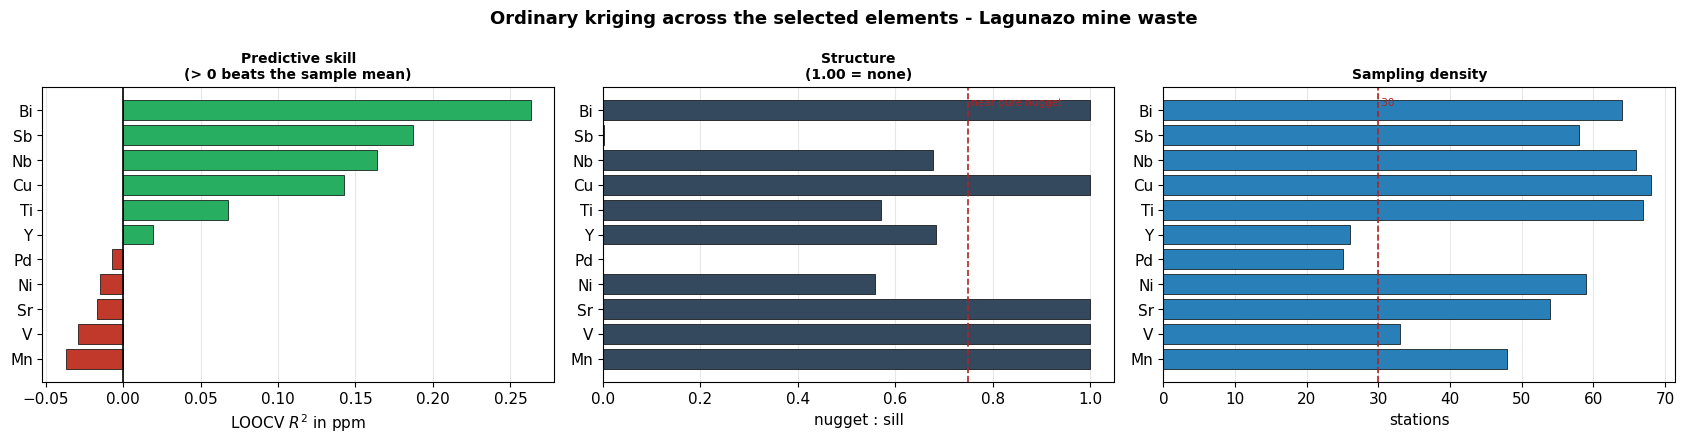

Manifest  -> results\run_manifest.json
Screening -> results\screening.csv
Summary   -> results\summary_all_elements.csv
Trials    -> results\transform_trials.csv
Overview  -> results\overview_all_elements.png

Per element: results/<element>/  ->  _variogram.png, _crossvalidation.png,
             _grade_map.png, _stderr_map.png,
             _grade_ppm_UTM29N.asc + .prj + _UNITS.txt,
             _stderr_<unit>_UTM29N.asc + .prj + _UNITS.txt,
             _LOOCV_results.csv, _cv_metrics.csv, _run_summary.csv,
             _interpretation.txt, _variogram_log.txt


In [11]:
# STAGE 6: OVERVIEW AND MANIFEST
if len(SUMMARY) == 0:
    raise RuntimeError("SUMMARY is empty - see the Stage 2 diagnostics above.")

s = SUMMARY.sort_values("R2_ppm")
fig, axes = plt.subplots(1, 3, figsize=(17, max(4.5, 0.32 * len(s))))
ax = axes[0]
col = np.where(s["R2_ppm"] > 0, "#27ae60", "#c0392b")
ax.barh(s["Element"], s["R2_ppm"], color=col, edgecolor="black", lw=0.5)
ax.axvline(0, color="black", lw=1.2)
ax.set_xlabel("LOOCV $R^2$ in ppm")
ax.set_title("Predictive skill\n(> 0 beats the sample mean)", fontsize=10,
             fontweight="bold")
ax.grid(axis="x", alpha=0.3)

ax = axes[1]
ax.barh(s["Element"], s["Nugget_sill"], color="#34495e", edgecolor="black", lw=0.5)
ax.axvline(0.75, color="firebrick", ls="--", lw=1.2)
ax.text(0.75, len(s) - 0.5, " near pure nugget", color="firebrick", fontsize=7.5,
        va="top")
ax.set_xlim(0, 1.05)
ax.set_xlabel("nugget : sill")
ax.set_title("Structure\n(1.00 = none)", fontsize=10, fontweight="bold")
ax.grid(axis="x", alpha=0.3)

ax = axes[2]
ax.barh(s["Element"], s["n_stations"], color="#2980b9", edgecolor="black", lw=0.5)
ax.axvline(ADVISORY_STATIONS, color="firebrick", ls="--", lw=1.2)
ax.text(ADVISORY_STATIONS, len(s) - 0.5, f" {ADVISORY_STATIONS}", color="firebrick",
        fontsize=7.5, va="top")
ax.set_xlabel("stations")
ax.set_title("Sampling density", fontsize=10, fontweight="bold")
ax.grid(axis="x", alpha=0.3)
fig.suptitle("Ordinary kriging across the selected elements - Lagunazo mine waste",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "overview_all_elements.png"), dpi=FIG_DPI)
plt.show()

MANIFEST = dict(
    notebook="Final_Ordinary_Kriging_Lagunazo_Multielement_r10.ipynb",
    core_module=CORE_PATH,
    run_started_utc=RUN_STARTED,
    run_finished_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
    environment=ENV, inputs=INPUTS,
    config={k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
            for k, v in [
                ("ELEMENTS", ELEMENTS), ("MIN_STATIONS", MIN_STATIONS),
                ("MIN_PAIRS_TOTAL", MIN_PAIRS_TOTAL),
                ("MIN_DISTINCT_VALS", MIN_DISTINCT_VALS),
                ("ADVISORY_STATIONS", ADVISORY_STATIONS),
                ("STATION_TOL_M", STATION_TOL_M), ("AGGREGATE_METHOD", AGGREGATE_METHOD),
                ("NEGATIVE_POLICY", NEGATIVE_POLICY),
                ("TRANSFORM_CANDIDATES", TRANSFORM_CANDIDATES),
                ("TRANSFORM_SELECT_ON", TRANSFORM_SELECT_ON),
                ("TRANSFORM_MIN_GAIN_PCT", TRANSFORM_MIN_GAIN_PCT),
                ("LOG_BACKTRANSFORM", LOG_BACKTRANSFORM),
                ("NSCORE_TIE_METHOD", NSCORE_TIE_METHOD),
                ("N_LAGS_MAX", N_LAGS_MAX), ("MIN_PAIRS_LAG", MIN_PAIRS_LAG),
                ("VGM_BINNING", VGM_BINNING), ("CUTOFF_FACTOR", CUTOFF_FACTOR),
                ("ALLOW_INVALID_2D_MODELS", ALLOW_INVALID_2D_MODELS),
                ("SELECTION_TOL_PCT", SELECTION_TOL_PCT),
                ("RMSSE_PENALTY", RMSSE_PENALTY),
                ("STRICT_MODEL_ERRORS", STRICT_MODEL_ERRORS),
                ("K_NEIGHBORS", K_NEIGHBORS), ("MIN_NEIGHBORS", MIN_NEIGHBORS),
                ("SEARCH_RADIUS_FACTOR", SEARCH_RADIUS_FACTOR),
                ("MAX_COND_NUMBER", MAX_COND_NUMBER),
                ("EPSG_UTM", EPSG_UTM), ("USE_FINE_GRID", USE_FINE_GRID),
                ("FINE_GRID_DIVISOR", FINE_GRID_DIVISOR),
                ("MIN_GRID_NODES", MIN_GRID_NODES), ("MAX_GRID_NODES", MAX_GRID_NODES),
                ("SHOW_BASEMAP", SHOW_BASEMAP), ("BASEMAP_SOURCE", BASEMAP_SOURCE),
                ("BASEMAP_ALPHA", BASEMAP_ALPHA),
                ("UNCERTAINTY_MEASURE", UNCERTAINTY_MEASURE),
            ]},
    grid=dict(nx=len(GX), ny=len(GY), cellsize_m=CELLSIZE, square=bool(SQUARE_CELLS),
              nodes_total=int(len(GRID_PTS)), nodes_in_domain=int(INSIDE.sum()),
              xllcorner=float(GX.min() - CELLSIZE / 2),
              yllcorner=float(GY.min() - CELLSIZE / 2),
              polygon_ha=float(POLY.area / 1e4), polygon_holes=len(HOLES)),
    elements_available=ALL_ELEMENTS,
    elements_requested=ELEMENT_LIST,
    elements_admitted=ADMITTED,
    elements_rejected={e: w for e, w in REJECTED},
    elements_failed_stage2=STAGE2_FAILED,
    elements_kriged=sorted(FITS),
    map_metadata={k: v for k, v in MAPMETA.items()},
    basemap=dict(requested=bool(SHOW_BASEMAP), source=BASEMAP_SOURCE,
                 alpha=BASEMAP_ALPHA, zoom=str(BASEMAP_ZOOM),
                 drawn_on=sorted(el for el, m in MAPMETA.items()
                                 if m["grade"]["basemap"]["used"])),
    results={rec["Element"]: {k: (None if (isinstance(v, float) and not np.isfinite(v))
                                  else (v.item() if hasattr(v, "item") else v))
                              for k, v in rec.items()}
             for rec in SUMMARY.to_dict(orient="records")},
)
with open(os.path.join(OUT_DIR, "run_manifest.json"), "w") as fh:
    json.dump(MANIFEST, fh, indent=2, default=str)
print(f"Manifest  -> {os.path.join(OUT_DIR, 'run_manifest.json')}")
print(f"Screening -> {os.path.join(OUT_DIR, 'screening.csv')}")
print(f"Summary   -> {os.path.join(OUT_DIR, 'summary_all_elements.csv')}")
print(f"Trials    -> {os.path.join(OUT_DIR, 'transform_trials.csv')}")
print(f"Overview  -> {os.path.join(OUT_DIR, 'overview_all_elements.png')}")
print(f"\nPer element: {OUT_DIR}/<element>/  ->  _variogram.png, _crossvalidation.png,")
print(f"             _grade_map.png, _{UNCERTAINTY_MEASURE}_map.png,")
print("             _grade_ppm_UTM29N.asc + .prj + _UNITS.txt,")
print("             _stderr_<unit>_UTM29N.asc + .prj + _UNITS.txt,")
print("             _LOOCV_results.csv, _cv_metrics.csv, _run_summary.csv,")
print("             _interpretation.txt, _variogram_log.txt")